   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Missing Values:
Hours Studied                       0
Previous Scores                     0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index         

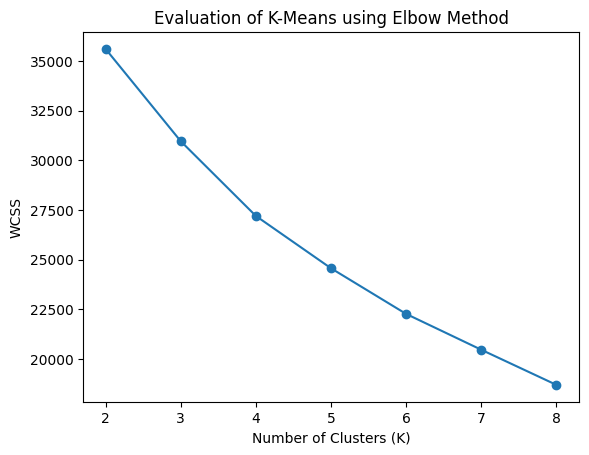

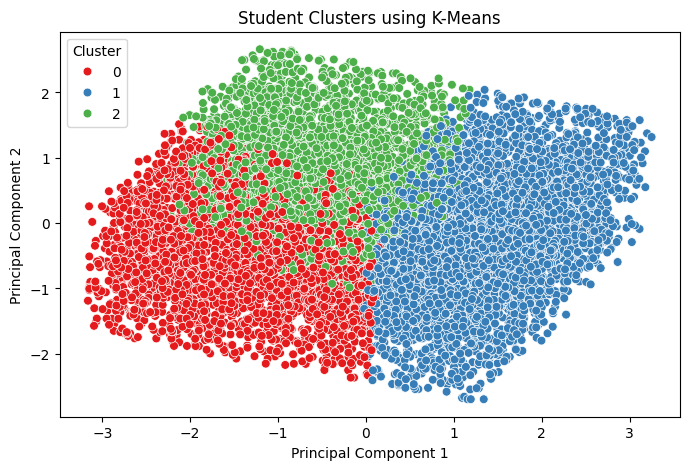


Cluster Characteristics:
         Hours Studied  Previous Scores  Sleep Hours  \
Cluster                                                
0                 2.60            57.29         6.46   
1                 5.21            86.58         6.58   
2                 7.24            56.42         6.54   

         Sample Question Papers Practiced  Performance Index  
Cluster                                                       
0                                    4.49              35.89  
1                                    4.66              73.41  
2                                    4.57              48.37  

Number of Students in Each Cluster:
Cluster
0    2996
1    4232
2    2772
Name: count, dtype: int64


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Load student dataset
df = pd.read_csv("Student_Performance.csv")
print(df.head())

# 2. Select numerical features
X = df[[
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Performance Index"
]]

# Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

# Handle missing values
X = X.fillna(X.median())

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit K-Means for different K values
wcss = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

    print("K =", k, " WCSS =", model.inertia_)

# 4. Plot Elbow Method
plt.plot(range(2, 9), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Evaluation of K-Means using Elbow Method")
plt.show()

# 5. Train final K-Means model
# Select K after observing the elbow graph
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

# 6. Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Cluster"],
    palette="Set1",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Clusters using K-Means")
plt.show()

# 7. Display cluster characteristics
print("\nCluster Characteristics:")
print(df.groupby("Cluster")[[
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Performance Index"
]].mean().round(2))

# Number of students in each cluster
print("\nNumber of Students in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())
